In [193]:
import pandas as pd
import numpy as np
import pandas_ta_classic
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
import matplotlib.pyplot as plt
keras.utils.set_random_seed(42)

SYMBOLS = [2140, 1120, 4220, 4180, 6020, 2030, 5110, 2070, 7010, 2060]
FEATURES = ['open', 'high', 'low', 'close',
    'alma_5_6.0_0.85', 'ldecay_5', 'dema_5', 'ema_5', 'fwma_5', 'hma_5', 'hl2', 'hlc3',
    'hwma_0.2_0.1_0.1', 'jma_5_0', 'kama_5_2_30', 'lr_5', 'median_5', 'midpoint_5',
    'midprice_5', 'pwma_5', 'qtl_5_0.5', 'rma_5', 'sinwma_5', 'sma_5', 'ssf_5_2',
    'swma_5', 't3_5_0.7', 'tema_5', 'trima_5', 'vwap_d', 'vwma_5', 'wcp', 'wma_5', 'zl_ema_5']


## Decisions vs. paper
- Step 1: zero-volume rows dropped; missing O/H/L filled from prev/today's close (paper: ffill)
- Step 3: library naming; 105 candidates pass vs. paper's 34 → paper's 34 used
- Step 7: shuffle=True; epochs ... (decided on val, see below)

In [169]:
raw = pd.read_csv('data/Tadawul_stcks.csv')
raw.columns = raw.columns.str.strip()
raw['date'] = pd.to_datetime(raw['date'])


In [196]:
def load_ticker(raw,symbol):
    df = raw[raw['symbol'] == symbol].copy()
    df = df.set_index('date').sort_index()
    assert df.index.is_unique
    df = df[df['volume_traded'] > 0]
    prev = df["close"].shift(1).fillna(df["close"]) 
    df["open"] = df["open"].fillna(prev)
    df["high"] = df["high"].fillna(np.maximum(prev, df["close"]))
    df["low"]  = df["low"].fillna(np.minimum(prev, df["close"]))
    df = df.rename(columns={"volume_traded": "volume"})[["open", "high", "low", "close", "volume"]]
    assert not df.isna().any().any()
    return df

def split(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Chronological train / val / test on the configured dates (bounds inclusive). Never shuffled."""
    train = df.loc[:'2015-12-31']
    val = df.loc['2016-01-01':'2016-12-31']
    test = df.loc['2017-01-01':'2020-03-05']
    return train, val, test

def all_indicators(df):
    parts = [df[['open','high','low','close','volume']]]
    failed = {}
    for name in df.ta.indicators(as_list=True):
        try:
            out = getattr(df.ta,name)(length=5, lookahead = False)
        except Exception as e:
            failed[name] = type(e).__name__
            continue
        if out is None:
            continue
        elif isinstance(out, pd.Series):
            # out.name = out.name.split("_", 1)[0]
            out.name = out.name.lower()
        elif isinstance(out, pd.DataFrame):
            # out.columns =  out.columns.str.split('_').str[0]
            out.columns =  out.columns.str.lower()
        parts.append(out)
    X = pd.concat(parts,axis=1)
    X = X.loc[:, ~X.columns.duplicated()]
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.dropna(axis=1, how='all')
    assert X.columns.is_unique
    return X, failed

def prepare(raw,symbol):
    X = all_indicators(load_ticker(raw,symbol))[0][FEATURES].dropna()
    train, val, test = split(X)
    x_scaler = StandardScaler().fit(train[FEATURES])
    y_scaler = StandardScaler().fit(train[["close"]])
    def scale(part):
        xs = pd.DataFrame(x_scaler.transform(part[FEATURES]), index=part.index, columns=FEATURES)
        ys = pd.Series(y_scaler.transform(part[['close']]).ravel(), index=part.index, name='y')
        return xs, ys
    return scale(train), scale(val), scale(test), x_scaler, y_scaler
def make_windows(X,y,w=5,h=5):
    n = len(X) - w - h + 1
    Xw = np.stack([X[i:i + w] for i in range(n)])
    Yw = np.stack([y[i + w:i + w + h] for i in range(n)])
    return Xw, Yw

def build_model(arch, units, lr=1e-3, w=5, n_features=34, h=5):
    layer = {
        'GRU':   lambda: keras.layers.GRU(units, activation='relu'),
        'LSTM':  lambda: keras.layers.LSTM(units, activation='relu'),
        'BiRNN': lambda: keras.layers.Bidirectional(keras.layers.SimpleRNN(units, activation='relu')),
    }[arch]()
    model = keras.Sequential([keras.Input(shape=(w, n_features)), layer, keras.layers.Dense(h)])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse')
    return model
def train(arch,units,Xwtr,ywtr,Xwva,ywva):
    model = build_model('GRU',64,1e-4)
    batch = int(0.1 * len(Xwtr))
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', 
                                        patience=20, 
                                        restore_best_weights=True)
    history = model.fit(Xwtr, ywtr, validation_data=(Xwva, ywva),
                        epochs=1000, batch_size=batch, shuffle=True, 
                        callbacks=[stop], verbose=2)
    return history

In [171]:
alrajhi = load_ticker(raw,1120)
(xtr, ytr), (xva, yva), (xte, yte), xs, ys = prepare(raw, 1120)
Xwtr, ywtr = make_windows(xtr, ytr)
Xwva, ywva = make_windows(xva, yva)

/home/ahmed/workspace/kfupm/ics619/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/ahmed/workspace/kfupm/ics619/.venv/lib/python3.12/site-packages/pandas_ta_classic/overlap/linreg.py:75: RuntimeWarning: invalid value encountered in sqrt
  rd = (divisor * (length * y2_sums - y_sums**2)) ** 0.5
/home/ahmed/workspace/kfupm/ics619/.venv/lib/python3.12/site-packages/pandas_ta_classic/overlap/linreg.py:76: RuntimeWarning: divide by zero encountered in divide
  return rn / rd
/home/ahmed/workspace/kfupm/ics619/.venv/lib/python3.12/site-packages/pandas_ta_classic/overlap/linreg.py:76: RuntimeWarning: invalid value encountered in divide
  return rn / rd
/home/ahmed/workspace/kfupm/ics619/.venv/lib/python3.12/site-packages/pandas_ta_classic/utils/_core.py:131: UserWarning: tos_stdevall() has no causal mode: one linear regression is fitted over the whole window, so every

In [172]:
print(xtr.mean().abs().max())
print(xtr.std().mean())
print(xva.mean().mean())
print(xte.mean().mean())

4.121879789988112e-16
1.0001355656482875
-0.255037033159137
0.5513889190963734


In [173]:
np.allclose(ys.inverse_transform(ytr.to_frame()).ravel(), alrajhi.loc[ytr.index, 'close'])

True

In [174]:
print(Xwtr.shape)
print(ywtr.shape)

(3680, 5, 34)
(3680, 5)


In [198]:
# model = build_model('GRU',64,1e-3)
# batch = int(0.1 * len(Xwtr))
# stop = keras.callbacks.EarlyStopping(monitor='val_loss', 
#                                      patience=20, 
#                                      restore_best_weights=True)
# history = model.fit(Xwtr, ywtr, validation_data=(Xwva, ywva),
#                     epochs=1000, batch_size=batch, shuffle=True, 
#                     callbacks=[stop], verbose=2)
history = train('GRU','64',Xwtr,ywtr,Xwva,ywva)

Epoch 1/1000


I0000 00:00:1793472372.095025   43686 dot_merger.cc:481] Merging Dots in computation: sequential_7_1_gru_7_1_while_body_128004_grad_128200_const_0__.16.clone.clone.clone.clone.clone
I0000 00:00:1793472372.095091   43686 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_128637__.17


10/10 - 2s - 189ms/step - loss: 0.8555 - val_loss: 0.1133
Epoch 2/1000
10/10 - 0s - 8ms/step - loss: 0.7047 - val_loss: 0.0984
Epoch 3/1000
10/10 - 0s - 8ms/step - loss: 0.5786 - val_loss: 0.0857
Epoch 4/1000
10/10 - 0s - 7ms/step - loss: 0.4762 - val_loss: 0.0749
Epoch 5/1000
10/10 - 0s - 7ms/step - loss: 0.3955 - val_loss: 0.0657
Epoch 6/1000
10/10 - 0s - 7ms/step - loss: 0.3329 - val_loss: 0.0578
Epoch 7/1000
10/10 - 0s - 7ms/step - loss: 0.2846 - val_loss: 0.0512
Epoch 8/1000
10/10 - 0s - 7ms/step - loss: 0.2497 - val_loss: 0.0457
Epoch 9/1000
10/10 - 0s - 7ms/step - loss: 0.2241 - val_loss: 0.0408
Epoch 10/1000
10/10 - 0s - 7ms/step - loss: 0.2010 - val_loss: 0.0359
Epoch 11/1000
10/10 - 0s - 7ms/step - loss: 0.1792 - val_loss: 0.0314
Epoch 12/1000
10/10 - 0s - 7ms/step - loss: 0.1595 - val_loss: 0.0273
Epoch 13/1000
10/10 - 0s - 7ms/step - loss: 0.1415 - val_loss: 0.0236
Epoch 14/1000
10/10 - 0s - 8ms/step - loss: 0.1244 - val_loss: 0.0202
Epoch 15/1000
10/10 - 0s - 7ms/step - lo

In [ ]:
# ci = FEATURES.index('close')
# naive = np.repeat(Xwva[:, -1, ci:ci+1], 5, axis=1)
# print('naive', np.mean((naive - ywva)**2), 'gru', model.evaluate(Xwva, ywva, verbose=0))

naive 0.0015624527075884008 gru 0.0016085240058600903


Text(0.5, 0, 'epoch')

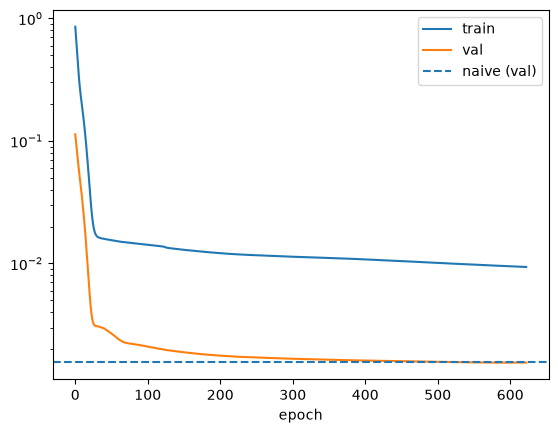

In [199]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.axhline(0.001562, ls='--', label='naive (val)')
plt.yscale('log'); plt.legend(); plt.xlabel('epoch')

In [ ]:
# def to_riyal(a): return ys.inverse_transform(a.reshape(-1, 1)).reshape(a.shape)
# pred = model.predict(Xwva, verbose=0)
# y_r, p_r, n_r = to_riyal(ywva), to_riyal(pred), to_riyal(naive)
# print('gru  ', np.sqrt(((p_r - y_r)**2).mean(axis=0)).round(3))
# print('naive', np.sqrt(((n_r - y_r)**2).mean(axis=0)).round(3))

gru   [0.513 0.713 0.843 1.029 1.15 ]
naive [0.488 0.708 0.845 0.992 1.147]
